In [111]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyod.models.iforest import IForest
from pyod.models.lof import LOF

 

In [112]:

np.random.seed(32)
# monto frecuencia baja
monto_normal1 = np.random.normal(loc=300, scale=90, size=600)
ops_normal1 = np.random.normal(loc=12, scale=0.8, size=600)

# monto medio frecuencia alta
monto_normal2 = np.random.normal(loc=1500, scale=200, size=350)
ops_normal2 = np.random.normal(loc=12, scale=2, size=350)

# fraudulentas
monto_fraude = np.random.uniform(low=6000, high=12000, size=50)
ops_fraude = np.random.uniform(low=20, high=40, size=50)


# concatenar los datos
XMONTO = np.concatenate((monto_normal1, monto_normal2, monto_fraude))
XOPS = np.concatenate((ops_normal1, ops_normal2, ops_fraude))

df = pd.DataFrame({'Monto': XMONTO, 'Operaciones': XOPS})

In [113]:
contaminacion = 0.05
X = df.values

# Entrenamineto iForest
clf_iforest = IForest(
    n_estimators=100,
    contamination=contaminacion,
    random_state=9
)

clf_iforest.fit(X)


df['iforest_Labels'] = clf_iforest.labels_
df['iforest_Scores'] = clf_iforest.decision_scores_

# Entrenamiento LOF
clt_lof = LOF(
    n_neighbors=25,
    contamination=contaminacion,
)

clt_lof.fit(X)

df['lof_Labels'] = clt_lof.labels_
df['lof_Scores'] = clt_lof.decision_scores_

print('Resumen')
print(f'Umbral IForest: {clf_iforest.threshold_:.8f}')
print(f'Anomalias detectadas IForest: {df["iforest_Labels"].sum()}')
print(f'Umbral LOF: {clt_lof.threshold_:.8f}')
print(f'Anomalias detectadas LOF: {df["lof_Labels"].sum()}')


Resumen
Umbral IForest: -0.00000000
Anomalias detectadas IForest: 50
Umbral LOF: 1.26690602
Anomalias detectadas LOF: 50


In [114]:
def detector_iforest(transaction):
    prediction = clf_iforest.predict(transaction)
    return "Fraudulenta" if prediction[0] == 1 else "Normal"

def detector_lof(transaction):
    prediction = clt_lof.predict(transaction)
    return "Fraudulenta" if prediction[0] == 1 else "Normal"

In [115]:
new_transaction = np.array([[10_000, 69]])

print(f'La transacción {new_transaction} es: {detector_iforest(new_transaction)} según IForest')
print(f'La transacción {new_transaction} es: {detector_lof(new_transaction)} según LOF')

La transacción [[10000    69]] es: Fraudulenta según IForest
La transacción [[10000    69]] es: Normal según LOF


Text(0.5, 1.0, 'Detección de Anomalías con LOF')

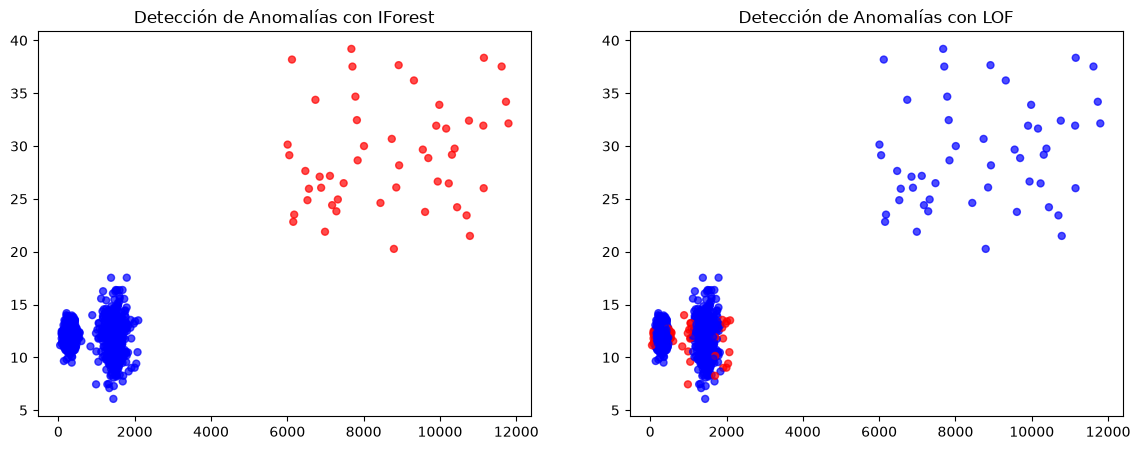

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#IForest
colores_iforest = np.where(df['iforest_Labels'] == 0, 'blue', 'red')
axes[0].scatter(df['Monto'], df['Operaciones'], c=colores_iforest, s=25, alpha=0.7)
axes[0].set_title('Detección de Anomalías con IForest')

#LOF
colores_lof = np.where(df['lof_Labels'] == 0, 'blue', 'red')
axes[1].scatter(df['Monto'], df['Operaciones'], c=colores_lof, s=25, alpha=0.7)
axes[1].set_title('Detección de Anomalías con LOF')



In [117]:
np.random.seed(40)


# Motor en reposo
rmp_b = np.random.normal(loc=800, scale=40, size=600)
temp_b = np.random.normal(loc=42, scale=40, size=600)
vib_b = np.random.normal(loc=1.2, scale=0.15, size=600)

# motor trabajando
rmp_a = np.random.normal(loc=3_200, scale=120, size=600)
temp_a = np.random.normal(loc=82, scale=4, size=600)
vib_a = np.random.normal(loc=3.8, scale=0.3, size=600)

# Dotos poligros
rmp_peli = np.array([820,850, 840, 830, 810])
temp_peli = np.array([84,86,85,87,83])
vib_peli = np.array([3.9,4.1,4.0,4.2,3.8])


rmp = np.concatenate((rmp_b, rmp_a, rmp_peli))
temp = np.concatenate((temp_b, temp_a, temp_peli))
vib = np.concatenate((vib_b, vib_a, vib_peli))

df_sensor = pd.DataFrame({'RPM': rmp, 'Temperatura': temp, 'Vibracion': vib})

X = df_sensor.values


# Alerta tradicional
def alerta_tradicional(rpm, temp, vib):
    if temp > 90 or vib > 5:
        return 1
    return 0

# Con IForest
contaminacion = len(rmp_peli) / len(df_sensor)
modelo_iforest = IForest(
    contamination=contaminacion,
    random_state=42,
)
modelo_iforest.fit(X)





df_sensor['alarma'] = df_sensor.apply(lambda row: alerta_tradicional(row['RPM'], row['Temperatura'], row['Vibracion']), axis=1)
df_sensor['iforest_Labels'] = modelo_iforest.labels_
df_sensor['iforest_Scores'] = modelo_iforest.decision_scores_



indice = list(range(len(df_sensor)-5, len(df_sensor)))


print('-------- RESUMEN --------')
print(f'Fallas detectadas por metodo tradicional: {df_sensor.loc[indice,"alarma"].sum()}')
print(f'Fallas detectadas por IForest: {df_sensor.loc[indice,"iforest_Labels"].sum()}')



print('-------- Las Fallas --------')
print(df_sensor.loc[indice, ['RPM', 'Temperatura', 'Vibracion', 'alarma', 'iforest_Labels']])

-------- RESUMEN --------
Fallas detectadas por metodo tradicional: 0
Fallas detectadas por IForest: 1
-------- Las Fallas --------
        RPM  Temperatura  Vibracion  alarma  iforest_Labels
1200  820.0         84.0        3.9       0               0
1201  850.0         86.0        4.1       0               0
1202  840.0         85.0        4.0       0               0
1203  830.0         87.0        4.2       0               1
1204  810.0         83.0        3.8       0               0


In [118]:
df

,Monto,Operaciones,iforest_Labels,iforest_Scores,lof_Labels,lof_Scores
0,268.599499,12.742647,0,-0.243863,0,0.989512
1,388.533309,11.389987,0,-0.240254,0,0.983168
2,352.283055,10.119238,0,-0.151745,0,1.091071
3,306.325600,12.286774,0,-0.266381,0,0.964743
4,369.977941,11.320538,0,-0.244386,0,0.997001
...,...,...,...,...,...,...
995,7843.313096,28.645966,1,0.037768,0,0.964905
996,6180.302556,23.511694,1,0.055112,0,1.076449
997,7823.527667,32.454248,1,0.059154,0,0.965358
998,7678.444814,39.193986,1,0.099674,0,0.984888
